SENTIMENT DATASET

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df=pd.read_csv('../Datasets/sentiment.csv')

In [4]:
df.head()

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,Enjoying a beautiful day at the park! ...,Positive,15-01-2023 12:30,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,1,Traffic was terrible this morning. ...,Negative,15-01-2023 08:45,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,2,Just finished an amazing workout! 💪 ...,Positive,15-01-2023 15:45,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,3,Excited about the upcoming weekend getaway! ...,Positive,15-01-2023 18:20,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,4,Trying out a new recipe for dinner tonight. ...,Neutral,15-01-2023 19:55,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         732 non-null    int64 
 1   Text       732 non-null    object
 2   Sentiment  732 non-null    object
 3   Timestamp  732 non-null    object
 4   User       732 non-null    object
 5   Platform   732 non-null    object
 6   Hashtags   732 non-null    object
 7   Retweets   732 non-null    int64 
 8   Likes      732 non-null    int64 
 9   Country    732 non-null    object
 10  Year       732 non-null    int64 
 11  Month      732 non-null    int64 
 12  Day        732 non-null    int64 
 13  Hour       732 non-null    int64 
dtypes: int64(7), object(7)
memory usage: 80.2+ KB


In [6]:
df['Country']=df['Country'].str.strip()

In [7]:
df['Text']=df['Text'].str.strip().str.lower()

In [8]:
df['Text']

0                  enjoying a beautiful day at the park!
1                     traffic was terrible this morning.
2                    just finished an amazing workout! 💪
3            excited about the upcoming weekend getaway!
4            trying out a new recipe for dinner tonight.
                             ...                        
727    collaborating on a science project that receiv...
728    attending a surprise birthday party organized ...
729    successfully fundraising for a school charity ...
730    participating in a multicultural festival, cel...
731    organizing a virtual talent show during challe...
Name: Text, Length: 732, dtype: object

In [9]:
df['Sentiment']=df['Sentiment'].str.strip().str.lower()

In [10]:
df['Sentiment']

0      positive
1      negative
2      positive
3      positive
4       neutral
         ...   
727       happy
728       happy
729       happy
730       happy
731       happy
Name: Sentiment, Length: 732, dtype: object

In [11]:
pd.unique(df['Sentiment'])

array(['positive', 'negative', 'neutral', 'anger', 'fear', 'sadness',
       'disgust', 'happiness', 'joy', 'love', 'amusement', 'enjoyment',
       'admiration', 'affection', 'awe', 'disappointed', 'surprise',
       'acceptance', 'adoration', 'anticipation', 'bitter', 'calmness',
       'confusion', 'excitement', 'kind', 'pride', 'shame', 'elation',
       'euphoria', 'contentment', 'serenity', 'gratitude', 'hope',
       'empowerment', 'compassion', 'tenderness', 'arousal', 'enthusiasm',
       'fulfillment', 'reverence', 'despair', 'grief', 'loneliness',
       'jealousy', 'resentment', 'frustration', 'boredom', 'anxiety',
       'intimidation', 'helplessness', 'envy', 'regret', 'curiosity',
       'indifference', 'numbness', 'melancholy', 'nostalgia',
       'ambivalence', 'determination', 'zest', 'hopeful', 'proud',
       'grateful', 'empathetic', 'compassionate', 'playful',
       'free-spirited', 'inspired', 'confident', 'bitterness', 'yearning',
       'fearful', 'apprehensiv

In [12]:
df1=df.groupby('Sentiment')['Text'].value_counts().reset_index(name='Count')

In [13]:
df1=df1.groupby('Sentiment')['Count'].sum().reset_index(name='TextCount')

In [14]:
df1=df1.sort_values(by='TextCount',ascending=False)

In [15]:
df1=df1.head(20)

C:\Users\Samarth\AppData\Local\Temp\ipykernel_9236\2458327600.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df1['Sentiment'],y=df1['TextCount'],palette='viridis')


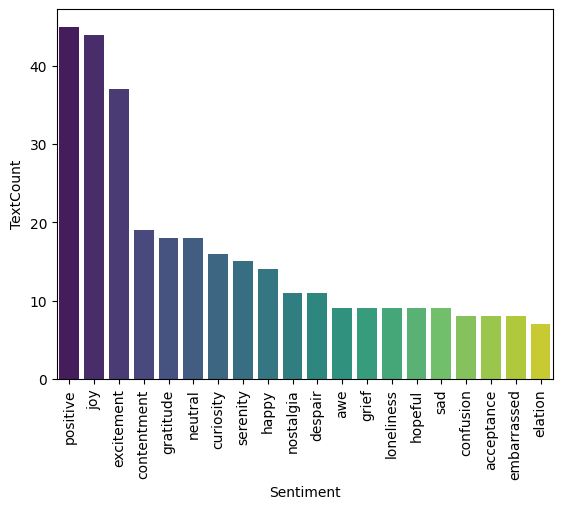

In [16]:
sns.barplot(x=df1['Sentiment'],y=df1['TextCount'],palette='viridis')
plt.xticks(rotation=90)
plt.show()

C:\Users\Samarth\AppData\Local\Temp\ipykernel_9236\3017466730.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df1['Sentiment'],y=df1['Sentiment'].str.len(),palette='viridis')


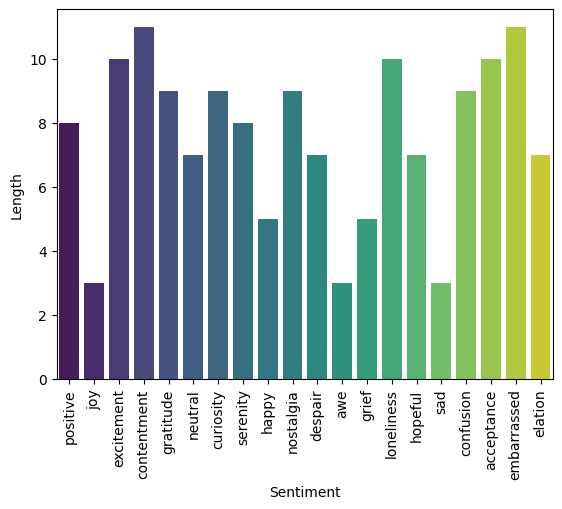

In [17]:
sns.barplot(x=df1['Sentiment'],y=df1['Sentiment'].str.len(),palette='viridis')
plt.ylabel('Length')
plt.xticks(rotation=90)
plt.show()

In [18]:
df2=df.groupby('Text')['Likes'].sum().reset_index(name='TotalLikes')

In [19]:
df2[df2['TotalLikes']==df2['TotalLikes'].max()]['Text']

14    a playful escapade in the carnival of life, ca...
Name: Text, dtype: object

In [20]:
df3=df.groupby('Text')['Retweets'].sum().reset_index(name='TotalReposts')

In [21]:
df3

,Text,TotalReposts
0,a bitter experience turned into a valuable les...,18
1,a burst of artistic creativity in the quietude...,15
2,a burst of creativity in the quiet solitude of...,15
3,"a compassionate rain, tears of empathy falling...",63
4,a cozy evening with a good movie.,18
...,...,...
701,wonderment at the beauty of a double rainbow a...,35
702,"wrapped in the cloak of emotional numbness, a ...",20
703,"wrestling with thoughts, a perplexed mind lost...",14
704,"yearning for a touch that's not there, echoes ...",10


In [22]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 706 entries, 0 to 705
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Text          706 non-null    object
 1   TotalReposts  706 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 11.2+ KB


In [23]:
df3[df3['TotalReposts']==df3['TotalReposts'].max()][['Text','TotalReposts']]

,Text,TotalReposts
14,"a playful escapade in the carnival of life, ca...",72


In [24]:
df[df['Text'].str.startswith('a playful escapade in the carnival of life')]['Sentiment']

267    playful
281    playful
295    playful
Name: Sentiment, dtype: object

In [25]:
df.columns

Index(['ID', 'Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags',
       'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour'],
      dtype='object')

In [26]:
df4=df[df['Sentiment']=='positive']

In [27]:
pd.unique(df4['Country'])

array(['USA', 'UK', 'India', 'Canada', 'Australia'], dtype=object)

In [28]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45 entries, 0 to 647
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         45 non-null     int64 
 1   Text       45 non-null     object
 2   Sentiment  45 non-null     object
 3   Timestamp  45 non-null     object
 4   User       45 non-null     object
 5   Platform   45 non-null     object
 6   Hashtags   45 non-null     object
 7   Retweets   45 non-null     int64 
 8   Likes      45 non-null     int64 
 9   Country    45 non-null     object
 10  Year       45 non-null     int64 
 11  Month      45 non-null     int64 
 12  Day        45 non-null     int64 
 13  Hour       45 non-null     int64 
dtypes: int64(7), object(7)
memory usage: 5.3+ KB


In [29]:
d=df4['Country'].value_counts().reset_index(name='Count')

In [30]:
d

,Country,Count
0,USA,18
1,UK,10
2,Canada,8
3,India,7
4,Australia,2


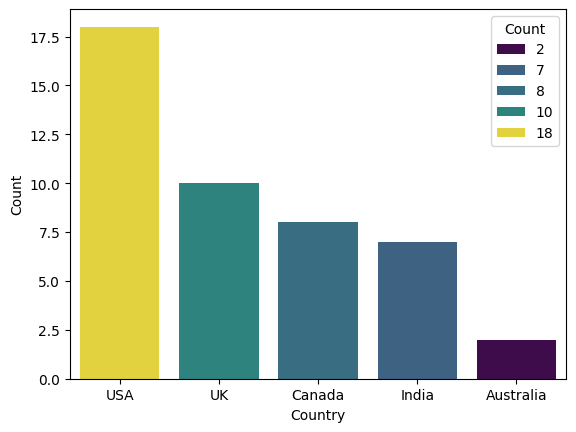

In [37]:
sns.barplot(x=d['Country'],y=d['Count'],hue=d['Count'],palette='viridis')
plt.show()

In [ ]:
df5=df[df['Text'].str.contains('travel')]

In [ ]:
df5

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
358,359,appreciation for the vibrant culture experienc...,appreciation,14-11-2016 13:45,CultureExplorer,Twitter,#Appreciation #CulturalExperience,28,55,UK,2016,11,14,13
561,562,"embarking on a spontaneous road trip, the trav...",adventure,28-09-2019 20:30,TravelEnthusiastRoadTripDiscovery,Twitter,#Adventure #RoadTripMemories,35,70,USA,2019,9,28,20
579,580,exploring the historical architecture of an an...,whispers of the past,18-04-2019 20:30,HistoryExplorerAncientCityTour,Twitter,#WhispersOfThePast #HistoricalTour,35,70,Greece,2019,4,18,20
596,597,spontaneously booked a weekend getaway. advent...,excitement,05-06-2023 10:00,AdventureSeeker,Instagram,#GetawayGoals #TeenTravel,18,35,UK,2023,6,5,10
610,611,embarked on a road trip to revisit cherished p...,joy,19-06-2023 16:30,RoadTripSenior,Facebook,#CherishedPlaces #SeniorTravel,22,45,Canada,2023,6,19,16
622,623,"embarked on a solo travel adventure, discoveri...",excitement,01-07-2023 14:00,SoloAdventurer,Instagram,#DiscoverNewPlaces #SeniorTravel,30,60,USA,2023,7,1,14
680,681,building a time capsule to capture memories fo...,joy,08-09-2023 14:15,TimeCapsuleCreatorHighSchool,Facebook,#TimeCapsule #HighSchoolNostalgia,26,48,Canada,2023,9,8,14


In [ ]:
df6=df[(df['Sentiment']=='positive') & (df['Year']==2023)]

In [ ]:
df6=df6.sort_values(by='Likes',ascending=False)

In [ ]:
df6.head(5)

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
22,22,productive day ticking off my to-do list.,positive,21-01-2023 16:45,ProductivityPro,Instagram,#Productivity #WorkFromHome,30,60,USA,2023,1,21,16
32,33,coding a new project with enthusiasm.,positive,25-01-2023 13:15,CodeEnthusiast,Facebook,#Coding #Enthusiasm,30,60,USA,2023,1,25,13
39,40,excited about the upcoming gaming tournament.,positive,28-01-2023 09:00,GamingEnthusiast,Instagram,#Gaming #Tournament,30,60,USA,2023,1,28,9
46,47,attending a virtual reality meetup.,positive,30-01-2023 18:30,VRMeetup,Twitter,#VRMeetup #VirtualReality,28,55,India,2023,1,30,18
13,13,"new year, new fitness goals! 💪",positive,18-01-2023 18:00,FitJourney,Instagram,#NewYear #FitnessGoals,28,55,USA,2023,1,18,18


In [ ]:
df7=df[df['Sentiment']=='happiness']['User']

In [ ]:
df7

56         ProudFriend     
80         NewParentJoy    
367     SunnyDayEnthusiast 
471         EchoedLaughter 
488       LaughterSymphony 
Name: User, dtype: object

In [ ]:
df8=df[(df['Sentiment']=='positive')|(df['Sentiment']=='negative')|(df['Sentiment']=='neutral')]

In [ ]:
df8

,ID,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,enjoying a beautiful day at the park!,positive,15-01-2023 12:30,User123,Twitter,#Nature #Park,15,30,USA,2023,1,15,12
1,1,traffic was terrible this morning.,negative,15-01-2023 08:45,CommuterX,Twitter,#Traffic #Morning,5,10,Canada,2023,1,15,8
2,2,just finished an amazing workout! 💪,positive,15-01-2023 15:45,FitnessFan,Instagram,#Fitness #Workout,20,40,USA,2023,1,15,15
3,3,excited about the upcoming weekend getaway!,positive,15-01-2023 18:20,AdventureX,Facebook,#Travel #Adventure,8,15,UK,2023,1,15,18
4,4,trying out a new recipe for dinner tonight.,neutral,15-01-2023 19:55,ChefCook,Instagram,#Cooking #Food,12,25,Australia,2023,1,15,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
713,714,participating in a science fair to showcase a ...,neutral,11-10-2023 16:45,ScienceFairParticipationHighSchool,Facebook,#ScienceFair #HighSchoolScience,19,37,USA,2023,10,11,16
714,715,attending a workshop on time management to enh...,neutral,12-10-2023 18:20,TimeManagementWorkshopHighSchool,Twitter,#EfficiencyGoals #HighSchoolSkills,23,44,Canada,2023,10,12,18
715,716,volunteering at a local charity event to give ...,neutral,13-10-2023 12:30,CharityEventVolunteerHighSchool,Instagram,#CommunityService #HighSchoolVolunteer,20,39,UK,2023,10,13,12
716,717,collaborating on a group project to promote te...,neutral,14-10-2023 17:30,GroupProjectCollaborationHighSchool,Facebook,#TeamSpirit #HighSchoolProjects,18,35,USA,2023,10,14,17


In [ ]:
df9=df8.groupby(['Country','Year','Sentiment']).size().unstack(fill_value=0)

In [ ]:
df9

,Sentiment,negative,neutral,positive
Country,Year,,,
Australia,2023,0,2,2
Canada,2023,2,5,8
India,2023,0,1,7
UK,2023,0,4,10
USA,2023,2,6,18


In [ ]:
df9.columns

Index(['Country', 'Year', 'negative', 'neutral', 'positive'], dtype='object', name='Sentiment')

<Axes: xlabel='Country,Year'>

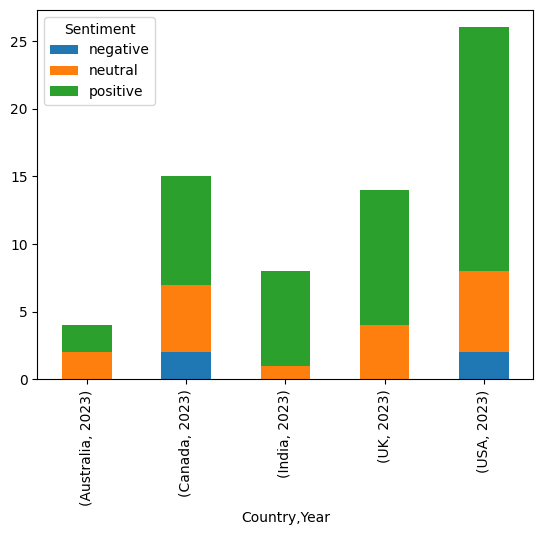

In [ ]:
df9.plot(stacked=True,kind='bar')